In [93]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# CONFIGURACIÓN DEL PROYECTO
# ============================================================

PROJECT_ROOT = Path.cwd().parent

print("Directorio de trabajo:")
print(Path.cwd())

print("\nPROJECT_ROOT:")
print(PROJECT_ROOT)

DATA_RAW = PROJECT_ROOT / "data" / "raw"

DATA_TABULAR = DATA_RAW / "tabular"
DATA_CLIMATE = DATA_RAW / "climate"
DATA_INTERIM = PROJECT_ROOT / "data" / "interim"


# ============================================================
# ARCHIVOS DE DATOS
# ============================================================

BASICO_PATH = (
    DATA_TABULAR /
    "Conjunto_datos_BASICO_AgroCebada2026.csv"
)

PRO_PATH = (
    DATA_TABULAR /
    "Conjunto_datos_PRO_AgroCebada.csv"
)

TARGET_PATH = (
    DATA_TABULAR /
    "ID_area_rendimiento_70_30_Reto_AgroCebada.csv"
)


# ============================================================
# VERIFICACIÓN DE RUTAS
# ============================================================

print("PROJECT_ROOT:")
print(PROJECT_ROOT)

print("\nArchivos principales:")

for path in [BASICO_PATH, PRO_PATH, TARGET_PATH]:
    print(f"{path.name}: {'OK' if path.exists() else 'NO ENCONTRADO'}")

Directorio de trabajo:
c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026\notebooks

PROJECT_ROOT:
c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026
PROJECT_ROOT:
c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026

Archivos principales:
Conjunto_datos_BASICO_AgroCebada2026.csv: OK
Conjunto_datos_PRO_AgroCebada.csv: OK
ID_area_rendimiento_70_30_Reto_AgroCebada.csv: OK


In [94]:
from pathlib import Path

# ============================================================
# CONFIGURACIÓN DE RUTAS — NOTEBOOK 06
# ============================================================

PROJECT_ROOT = Path.cwd().parent

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_INTERIM = PROJECT_ROOT / "data" / "interim"

# Resultados climáticos ya auditados
CHIRPS_PATH = (
    DATA_INTERIM
    / "climate"
    / "chirps_parcel_month_area_weighted.csv"
)

TMIN_PATH = (
    DATA_INTERIM
    / "climate"
    / "chirts_era5_tmin_parcel_month_area_weighted.csv"
)

TMAX_PATH = (
    DATA_INTERIM
    / "climate"
    / "chirts_era5_tmax_parcel_month_area_weighted.csv"
)

# Resultado topográfico ya auditado
TOPO_PATH = (
    DATA_INTERIM
    / "topography"
    / "topografia_parcelas.csv"
)

print("PROJECT_ROOT:")
print(PROJECT_ROOT)

print("\nArchivos:")
print("CHIRPS:", CHIRPS_PATH.exists(), CHIRPS_PATH)
print("TMIN:  ", TMIN_PATH.exists(), TMIN_PATH)
print("TMAX:  ", TMAX_PATH.exists(), TMAX_PATH)
print("TOPO:  ", TOPO_PATH.exists(), TOPO_PATH)

PROJECT_ROOT:
c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026

Archivos:
CHIRPS: True c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026\data\interim\climate\chirps_parcel_month_area_weighted.csv
TMIN:   True c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026\data\interim\climate\chirts_era5_tmin_parcel_month_area_weighted.csv
TMAX:   True c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026\data\interim\climate\chirts_era5_tmax_parcel_month_area_weighted.csv
TOPO:   True c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026\data\interim\topography\topografia_parcelas.csv


In [95]:
# Rutas de datos climáticos

CHIRPS_PATH = (
    DATA_INTERIM
    / "climate"
    / "chirps_parcel_month_area_weighted.csv"
)

TMIN_PATH = (
    DATA_INTERIM
    / "climate"
    / "chirts_era5_tmin_parcel_month_area_weighted.csv"
)

TMAX_PATH = (
    DATA_INTERIM
    / "climate"
    / "chirts_era5_tmax_parcel_month_area_weighted.csv"
)

print("Rutas climáticas configuradas.")
print("CHIRPS:", CHIRPS_PATH)
print("TMIN:", TMIN_PATH)
print("TMAX:", TMAX_PATH)

Rutas climáticas configuradas.
CHIRPS: c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026\data\interim\climate\chirps_parcel_month_area_weighted.csv
TMIN: c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026\data\interim\climate\chirts_era5_tmin_parcel_month_area_weighted.csv
TMAX: c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026\data\interim\climate\chirts_era5_tmax_parcel_month_area_weighted.csv


In [96]:
# Cargar datos climáticos

chirps = pd.read_csv(CHIRPS_PATH)
tmin = pd.read_csv(TMIN_PATH)
tmax = pd.read_csv(TMAX_PATH)

print("CHIRPS:", chirps.shape)
print("TMIN:", tmin.shape)
print("TMAX:", tmax.shape)

CHIRPS: (9456, 8)
TMIN: (9456, 6)
TMAX: (9456, 6)


In [97]:
# ============================================================
# IMPORTS
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [98]:
from pathlib import Path

# Obtener la raíz del proyecto a partir de una ruta que ya sabemos que existe
PROJECT_ROOT = Path(CHIRPS_PATH).parents[3]

# Ruta del archivo de topografía ya auditado
TOPO_PATH = (
    PROJECT_ROOT
    / "data"
    / "interim"
    / "topography"
    / "topografia_parcelas.csv"
)

# Cargar resultados topográficos
topografia = pd.read_csv(TOPO_PATH)

print("Archivo:", TOPO_PATH)
print("Shape:", topografia.shape)

print("\nColumnas:")
print(topografia.columns.tolist())

print("\nDuplicados ID:")
print(topografia["ID_POLIGON"].duplicated().sum())

print("\nIDs únicos:")
print(topografia["ID_POLIGON"].nunique())

Archivo: c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026\data\interim\topography\topografia_parcelas.csv
Shape: (197, 5)

Columnas:
['ID_POLIGON', 'slope_deg', 'slope_coverage', 'elevation_m', 'elevation_coverage']

Duplicados ID:
0

IDs únicos:
197


In [99]:
# Construir fecha mensual para CHIRPS

chirps["fecha"] = pd.to_datetime(
    chirps["year"].astype(str)
    + "-"
    + chirps["month"].astype(str)
    + "-01"
)

print("Filas:", len(chirps))
print("Parcelas:", chirps["ID_POLIGON"].nunique())
print("Fechas únicas:", chirps["fecha"].nunique())
print(
    "Rango:",
    chirps["fecha"].min().date(),
    "→",
    chirps["fecha"].max().date()
)

Filas: 9456
Parcelas: 197
Fechas únicas: 48
Rango: 2022-01-01 → 2025-12-01


In [100]:
# ============================================================
# CARGA DE DATOS
# ============================================================

basico = pd.read_csv(BASICO_PATH)
pro = pd.read_csv(PRO_PATH)
target = pd.read_csv(TARGET_PATH)


# ============================================================
# CONVERSIÓN DE FECHAS
# ============================================================

basico["fecha_captura"] = pd.to_datetime(
    basico["fecha_captura"],
    format="%d/%m/%Y",
    errors="coerce"
)
pro["fecha_captura"] = pd.to_datetime(
    pro["fecha_captura"],
    format="%d/%m/%Y",
    errors="coerce"
)


# ============================================================
# RESUMEN GENERAL
# ============================================================

print("BÁSICO")
print(f"Shape: {basico.shape}")
print(f"Fecha mínima: {basico['fecha_captura'].min()}")
print(f"Fecha máxima: {basico['fecha_captura'].max()}")
print(f"Parcelas: {basico['ID_POLIGONO'].nunique()}")
print(f"Sensores: {basico['sensor'].unique().tolist()}")


print("\nPRO")
print(f"Shape: {pro.shape}")
print(f"Fecha mínima: {pro['fecha_captura'].min()}")
print(f"Fecha máxima: {pro['fecha_captura'].max()}")
print(f"Parcelas: {pro['ID_POLIGONO'].nunique()}")
print(f"Sensores: {pro['sensor'].unique().tolist()}")


print("\nTARGET")
print(f"Shape: {target.shape}")
print(f"Parcelas: {target['ID_POLIGONO'].nunique()}")
print(f"Conjuntos: {target['CONJUNTO'].value_counts().to_dict()}")

BÁSICO
Shape: (107666, 96)
Fecha mínima: 2022-01-01 00:00:00
Fecha máxima: 2025-12-31 00:00:00
Parcelas: 197
Sensores: ['Landsat', 'Sentinel-2']

PRO
Shape: (47804, 20)
Fecha mínima: 2025-01-01 00:00:00
Fecha máxima: 2025-12-30 00:00:00
Parcelas: 197
Sensores: ['Planet']

TARGET
Shape: (197, 5)
Parcelas: 197
Conjuntos: {'ENTRENAMIENTO': 138, 'PREDICCION': 59}


In [101]:
# ============================================================
# AUDITORÍA DEL FORMATO DE FECHAS
# ============================================================

print("BÁSICO - ejemplos de fechas originales:")
print(basico["fecha_captura"].head(10).tolist())

print("\nPRO - ejemplos de fechas originales:")
print(pro["fecha_captura"].head(10).tolist())

print("\nPRO - tipos de dato:")
print(pro["fecha_captura"].dtype)

print("\nPRO - fechas únicas problemáticas para interpretación:")
print(
    pro["fecha_captura"]
    .dropna()
    .astype(str)
    .head(20)
    .tolist()
)

BÁSICO - ejemplos de fechas originales:
[Timestamp('2022-04-20 00:00:00'), Timestamp('2024-03-16 00:00:00'), Timestamp('2024-03-15 00:00:00'), Timestamp('2025-08-26 00:00:00'), Timestamp('2025-03-10 00:00:00'), Timestamp('2022-10-04 00:00:00'), Timestamp('2025-03-11 00:00:00'), Timestamp('2025-07-29 00:00:00'), Timestamp('2024-08-03 00:00:00'), Timestamp('2024-02-20 00:00:00')]

PRO - ejemplos de fechas originales:
[Timestamp('2025-02-05 00:00:00'), Timestamp('2025-02-08 00:00:00'), Timestamp('2025-02-07 00:00:00'), Timestamp('2025-02-09 00:00:00'), Timestamp('2025-01-30 00:00:00'), Timestamp('2025-02-02 00:00:00'), Timestamp('2025-02-04 00:00:00'), Timestamp('2025-02-03 00:00:00'), Timestamp('2025-08-02 00:00:00'), Timestamp('2025-02-17 00:00:00')]

PRO - tipos de dato:
datetime64[us]

PRO - fechas únicas problemáticas para interpretación:
['2025-02-05', '2025-02-08', '2025-02-07', '2025-02-09', '2025-01-30', '2025-02-02', '2025-02-04', '2025-02-03', '2025-08-02', '2025-02-17', '2025-

In [102]:
# ============================================================
# CONVERSIÓN CONTROLADA DE FECHAS PRO
# ============================================================

pro["fecha_captura"] = pd.to_datetime(
    pro["fecha_captura"],
    format="%d/%m/%Y",
    errors="coerce"
)


# ============================================================
# VALIDACIÓN DE LA CONVERSIÓN
# ============================================================

print("Tipo de dato:")
print(pro["fecha_captura"].dtype)

print("\nFechas mínimas y máximas:")
print(f"Mínima: {pro['fecha_captura'].min()}")
print(f"Máxima: {pro['fecha_captura'].max()}")

print("\nValores que no pudieron convertirse:")
print(pro["fecha_captura"].isna().sum())

print("\nPrimeras fechas convertidas:")
print(pro["fecha_captura"].head(10).tolist())

Tipo de dato:
datetime64[us]

Fechas mínimas y máximas:
Mínima: 2025-01-01 00:00:00
Máxima: 2025-12-30 00:00:00

Valores que no pudieron convertirse:
0

Primeras fechas convertidas:
[Timestamp('2025-02-05 00:00:00'), Timestamp('2025-02-08 00:00:00'), Timestamp('2025-02-07 00:00:00'), Timestamp('2025-02-09 00:00:00'), Timestamp('2025-01-30 00:00:00'), Timestamp('2025-02-02 00:00:00'), Timestamp('2025-02-04 00:00:00'), Timestamp('2025-02-03 00:00:00'), Timestamp('2025-08-02 00:00:00'), Timestamp('2025-02-17 00:00:00')]


In [103]:
# ============================================================
# COBERTURA TEMPORAL POR SENSOR
# ============================================================

print("BÁSICO — cobertura por sensor")
print(
    basico.groupby("sensor")["fecha_captura"]
    .agg(
        fecha_min="min",
        fecha_max="max",
        fechas_unicas="nunique",
        observaciones="size"
    )
)

print("\nPRO — cobertura temporal")
print(
    pro.groupby("sensor")["fecha_captura"]
    .agg(
        fecha_min="min",
        fecha_max="max",
        fechas_unicas="nunique",
        observaciones="size"
    )
)

BÁSICO — cobertura por sensor
            fecha_min  fecha_max  fechas_unicas  observaciones
sensor                                                        
Landsat    2022-01-05 2025-12-31            392          48626
Sentinel-2 2022-01-01 2025-12-31            301          59040

PRO — cobertura temporal
        fecha_min  fecha_max  fechas_unicas  observaciones
sensor                                                    
Planet 2025-01-01 2025-12-30            311          47804


In [104]:
# ============================================================
# COBERTURA DE PARCELAS POR FECHA
# ============================================================

TOTAL_PARCELAS = 197


# ------------------------------------------------------------
# BÁSICO — por sensor
# ------------------------------------------------------------

cobertura_basico = (
    basico
    .groupby(["sensor", "fecha_captura"])["ID_POLIGONO"]
    .nunique()
    .reset_index(name="parcelas_observadas")
)

cobertura_basico["cobertura_pct"] = (
    cobertura_basico["parcelas_observadas"]
    / TOTAL_PARCELAS
    * 100
)


# ------------------------------------------------------------
# PRO — Planet
# ------------------------------------------------------------

cobertura_pro = (
    pro
    .groupby("fecha_captura")["ID_POLIGONO"]
    .nunique()
    .reset_index(name="parcelas_observadas")
)

cobertura_pro["cobertura_pct"] = (
    cobertura_pro["parcelas_observadas"]
    / TOTAL_PARCELAS
    * 100
)


# ============================================================
# RESUMEN
# ============================================================

print("BÁSICO — cobertura por fecha y sensor")
print(
    cobertura_basico
    .groupby("sensor")["cobertura_pct"]
    .describe()
)

print("\nPRO — cobertura por fecha")
print(
    cobertura_pro["cobertura_pct"]
    .describe()
)

BÁSICO — cobertura por fecha y sensor
            count       mean        std        min         25%         50%  \
sensor                                                                       
Landsat     392.0  62.967471  37.868208   5.583756   22.335025   83.756345   
Sentinel-2  301.0  99.566589   3.454956  67.005076  100.000000  100.000000   

              75%    max  
sensor                    
Landsat     100.0  100.0  
Sentinel-2  100.0  100.0  

PRO — cobertura por fecha
count    311.000000
mean      78.025691
std       27.005931
min        2.030457
25%       61.928934
50%       91.370558
75%      100.000000
max      100.000000
Name: cobertura_pct, dtype: float64


In [105]:
# ============================================================
# COBERTURA TEMPORAL DURANTE 2025
# ============================================================

basico_2025 = basico[
    basico["fecha_captura"].dt.year == 2025
].copy()

pro_2025 = pro[
    pro["fecha_captura"].dt.year == 2025
].copy()


# ------------------------------------------------------------
# BÁSICO — 2025
# ------------------------------------------------------------

cobertura_basico_2025 = (
    basico_2025
    .groupby(["sensor", "fecha_captura"])["ID_POLIGONO"]
    .nunique()
    .reset_index(name="parcelas_observadas")
)

cobertura_basico_2025["cobertura_pct"] = (
    cobertura_basico_2025["parcelas_observadas"]
    / TOTAL_PARCELAS
    * 100
)


# ------------------------------------------------------------
# PRO — 2025
# ------------------------------------------------------------

cobertura_pro_2025 = (
    pro_2025
    .groupby("fecha_captura")["ID_POLIGONO"]
    .nunique()
    .reset_index(name="parcelas_observadas")
)

cobertura_pro_2025["cobertura_pct"] = (
    cobertura_pro_2025["parcelas_observadas"]
    / TOTAL_PARCELAS
    * 100
)


# ============================================================
# RESUMEN
# ============================================================

print("BÁSICO — 2025")
print(
    cobertura_basico_2025
    .groupby("sensor")["cobertura_pct"]
    .describe()
)

print("\nPRO — 2025")
print(
    cobertura_pro_2025["cobertura_pct"]
    .describe()
)

BÁSICO — 2025
            count       mean        std        min         25%         50%  \
sensor                                                                       
Landsat      90.0  61.680767  38.994764  11.167513   22.335025   72.588832   
Sentinel-2   86.0  99.279896   4.694178  69.035533  100.000000  100.000000   

              75%    max  
sensor                    
Landsat     100.0  100.0  
Sentinel-2  100.0  100.0  

PRO — 2025
count    311.000000
mean      78.025691
std       27.005931
min        2.030457
25%       61.928934
50%       91.370558
75%      100.000000
max      100.000000
Name: cobertura_pct, dtype: float64


In [106]:
# ============================================================
# COBERTURA TEMPORAL POR PARCELA — 2025
# ============================================================

# ------------------------------------------------------------
# BÁSICO
# ------------------------------------------------------------

cobertura_parcela_basico_2025 = (
    basico_2025
    .groupby(["sensor", "ID_POLIGONO"])["fecha_captura"]
    .nunique()
    .reset_index(name="fechas_observadas")
)


# ------------------------------------------------------------
# PRO — Planet
# ------------------------------------------------------------

cobertura_parcela_pro_2025 = (
    pro_2025
    .groupby("ID_POLIGONO")["fecha_captura"]
    .nunique()
    .reset_index(name="fechas_observadas")
)


# ============================================================
# RESUMEN
# ============================================================

print("BÁSICO — fechas por parcela durante 2025")
print(
    cobertura_parcela_basico_2025
    .groupby("sensor")["fechas_observadas"]
    .describe()
)

print("\nPRO — fechas por parcela durante 2025")
print(
    cobertura_parcela_pro_2025["fechas_observadas"]
    .describe()
)

BÁSICO — fechas por parcela durante 2025
            count       mean        std   min   25%   50%   75%   max
sensor                                                               
Landsat     197.0  55.512690  16.555907  45.0  45.0  45.0  62.0  90.0
Sentinel-2  197.0  85.380711   0.927050  84.0  84.0  86.0  86.0  86.0

PRO — fechas por parcela durante 2025
count    197.000000
mean     242.659898
std        4.418314
min      233.000000
25%      240.000000
50%      243.000000
75%      246.000000
max      251.000000
Name: fechas_observadas, dtype: float64


In [107]:
# ============================================================
# DISTRIBUCIÓN DE COBERTURA POR PARCELA — 2025
# ============================================================

print("Landsat — distribución de fechas observadas por parcela")
print(
    cobertura_parcela_basico_2025[
        cobertura_parcela_basico_2025["sensor"] == "Landsat"
    ]["fechas_observadas"]
    .value_counts()
    .sort_index()
)


print("\nSentinel-2 — distribución de fechas observadas por parcela")
print(
    cobertura_parcela_basico_2025[
        cobertura_parcela_basico_2025["sensor"] == "Sentinel-2"
    ]["fechas_observadas"]
    .value_counts()
    .sort_index()
)


print("\nPlanet — distribución de fechas observadas por parcela")
print(
    cobertura_parcela_pro_2025["fechas_observadas"]
    .value_counts()
    .sort_index()
)

Landsat — distribución de fechas observadas por parcela
fechas_observadas
45    108
47      3
48      2
49     14
50      4
51      5
52      2
53      6
54      2
60      1
62      1
63      1
64      3
65      1
68      1
69      1
70      3
71      2
73      2
74      1
80      1
82      2
86      2
87      1
89      6
90     22
Name: count, dtype: int64

Sentinel-2 — distribución de fechas observadas por parcela
fechas_observadas
84     61
86    136
Name: count, dtype: int64

Planet — distribución de fechas observadas por parcela
fechas_observadas
233     2
234     6
235     6
236    11
237     8
238    11
239     4
240    10
241    13
242    16
243    15
244    18
245    15
246    24
247    16
248     7
249     5
250     6
251     4
Name: count, dtype: int64


In [108]:
# ============================================================
# INVESTIGACIÓN DE LOS PATRONES DE LANDSAT
# ============================================================

landsat_parcela_2025 = cobertura_parcela_basico_2025[
    cobertura_parcela_basico_2025["sensor"] == "Landsat"
].copy()


parcelas_45 = landsat_parcela_2025.loc[
    landsat_parcela_2025["fechas_observadas"] == 45,
    "ID_POLIGONO"
].tolist()


parcelas_90 = landsat_parcela_2025.loc[
    landsat_parcela_2025["fechas_observadas"] == 90,
    "ID_POLIGONO"
].tolist()


print(f"Parcelas con 45 fechas: {len(parcelas_45)}")
print(f"Parcelas con 90 fechas: {len(parcelas_90)}")

print("\nEjemplos de parcelas con 45 fechas:")
print(parcelas_45[:10])

print("\nParcelas con 90 fechas:")
print(parcelas_90)

Parcelas con 45 fechas: 108
Parcelas con 90 fechas: 22

Ejemplos de parcelas con 45 fechas:
['AGC_001', 'AGC_003', 'AGC_004', 'AGC_007', 'AGC_009', 'AGC_018', 'AGC_019', 'AGC_020', 'AGC_022', 'AGC_023']

Parcelas con 90 fechas:
['AGC_008', 'AGC_011', 'AGC_013', 'AGC_031', 'AGC_033', 'AGC_056', 'AGC_062', 'AGC_073', 'AGC_082', 'AGC_084', 'AGC_088', 'AGC_094', 'AGC_096', 'AGC_115', 'AGC_137', 'AGC_139', 'AGC_151', 'AGC_152', 'AGC_165', 'AGC_186', 'AGC_190', 'AGC_195']


In [109]:
# ============================================================
# COMPARACIÓN DE CALENDARIOS LANDSAT
# ============================================================

# Seleccionamos una parcela representativa de cada grupo
parcela_45 = parcelas_45[0]
parcela_90 = parcelas_90[0]


fechas_45 = set(
    basico_2025.loc[
        (basico_2025["sensor"] == "Landsat") &
        (basico_2025["ID_POLIGONO"] == parcela_45),
        "fecha_captura"
    ]
)


fechas_90 = set(
    basico_2025.loc[
        (basico_2025["sensor"] == "Landsat") &
        (basico_2025["ID_POLIGONO"] == parcela_90),
        "fecha_captura"
    ]
)


# ============================================================
# COMPARACIÓN
# ============================================================

fechas_comunes = fechas_45.intersection(fechas_90)

solo_45 = fechas_45 - fechas_90
solo_90 = fechas_90 - fechas_45


print(f"Parcela grupo 45: {parcela_45}")
print(f"Parcela grupo 90: {parcela_90}")

print("\nNúmero de fechas:")
print(f"Grupo 45: {len(fechas_45)}")
print(f"Grupo 90: {len(fechas_90)}")
print(f"Fechas comunes: {len(fechas_comunes)}")
print(f"Solo grupo 45: {len(solo_45)}")
print(f"Solo grupo 90: {len(solo_90)}")

print("\n¿Las fechas del grupo 45 están contenidas en las del grupo 90?")
print(fechas_45.issubset(fechas_90))

print("\n¿Las fechas del grupo 90 están contenidas en las del grupo 45?")
print(fechas_90.issubset(fechas_45))

Parcela grupo 45: AGC_001
Parcela grupo 90: AGC_008

Número de fechas:
Grupo 45: 45
Grupo 90: 90
Fechas comunes: 45
Solo grupo 45: 0
Solo grupo 90: 45

¿Las fechas del grupo 45 están contenidas en las del grupo 90?
True

¿Las fechas del grupo 90 están contenidas en las del grupo 45?
False


In [110]:
# ============================================================
# VALIDACIÓN DEL CALENDARIO LANDSAT
# ============================================================

# Calendarios de todas las parcelas
calendarios_landsat = (
    basico_2025[basico_2025["sensor"] == "Landsat"]
    .groupby("ID_POLIGONO")["fecha_captura"]
    .apply(lambda x: frozenset(x))
    .to_dict()
)


# ============================================================
# CALENDARIOS DEL GRUPO DE 45
# ============================================================

calendarios_45 = {
    parcela: calendarios_landsat[parcela]
    for parcela in parcelas_45
}

# Número de calendarios únicos dentro del grupo de 45
calendarios_45_unicos = set(calendarios_45.values())

print("Grupo de 45 fechas")
print(f"Parcelas: {len(parcelas_45)}")
print(f"Calendarios únicos: {len(calendarios_45_unicos)}")


# ============================================================
# CALENDARIOS DEL GRUPO DE 90
# ============================================================

calendarios_90 = {
    parcela: calendarios_landsat[parcela]
    for parcela in parcelas_90
}

calendarios_90_unicos = set(calendarios_90.values())

print("\nGrupo de 90 fechas")
print(f"Parcelas: {len(parcelas_90)}")
print(f"Calendarios únicos: {len(calendarios_90_unicos)}")


# ============================================================
# COMPARACIÓN
# ============================================================

calendario_90_referencia = next(iter(calendarios_90_unicos))

subconjuntos_45 = {
    parcela: calendario.issubset(calendario_90_referencia)
    for parcela, calendario in calendarios_45.items()
}

print("\n¿Cada calendario de 45 es subconjunto del calendario de 90?")
print(all(subconjuntos_45.values()))

print(
    f"Parcelas que cumplen: "
    f"{sum(subconjuntos_45.values())}/{len(subconjuntos_45)}"
)

Grupo de 45 fechas
Parcelas: 108
Calendarios únicos: 1

Grupo de 90 fechas
Parcelas: 22
Calendarios únicos: 1

¿Cada calendario de 45 es subconjunto del calendario de 90?
True
Parcelas que cumplen: 108/108


In [111]:
# ============================================================
# INVESTIGACIÓN DE LAS PARCELAS LANDSAT INTERMEDIAS
# ============================================================

parcelas_extremos = set(parcelas_45) | set(parcelas_90)

parcelas_intermedias = [
    parcela
    for parcela in calendarios_landsat
    if parcela not in parcelas_extremos
]

print(f"Parcelas intermedias: {len(parcelas_intermedias)}")


# ============================================================
# NÚMERO DE CALENDARIOS ÚNICOS
# ============================================================

calendarios_intermedios = {
    parcela: calendarios_landsat[parcela]
    for parcela in parcelas_intermedias
}

calendarios_intermedios_unicos = set(
    calendarios_intermedios.values()
)

print(
    f"Calendarios únicos entre parcelas intermedias: "
    f"{len(calendarios_intermedios_unicos)}"
)


# ============================================================
# COMPARACIÓN CON EL CALENDARIO COMPLETO DE 90
# ============================================================

subconjuntos_90 = {
    parcela: calendario.issubset(calendario_90_referencia)
    for parcela, calendario in calendarios_intermedios.items()
}

print(
    "\nParcelas intermedias cuyo calendario es "
    "subconjunto del calendario de 90:"
)

print(
    f"{sum(subconjuntos_90.values())}/"
    f"{len(subconjuntos_90)}"
)


# ============================================================
# TAMAÑOS DE LOS CALENDARIOS
# ============================================================

print("\nDistribución de tamaños:")
print(
    pd.Series(
        {
            parcela: len(calendario)
            for parcela, calendario in calendarios_intermedios.items()
        }
    )
    .value_counts()
    .sort_index()
)

Parcelas intermedias: 67
Calendarios únicos entre parcelas intermedias: 24

Parcelas intermedias cuyo calendario es subconjunto del calendario de 90:
67/67

Distribución de tamaños:
47     3
48     2
49    14
50     4
51     5
52     2
53     6
54     2
60     1
62     1
63     1
64     3
65     1
68     1
69     1
70     3
71     2
73     2
74     1
80     1
82     2
86     2
87     1
89     6
Name: count, dtype: int64


In [112]:
# ============================================================
# DISTRIBUCIÓN MENSUAL DE LAS FECHAS LANDSAT
# ============================================================

# Calendario de referencia de 90 fechas
fechas_referencia_90 = sorted(calendario_90_referencia)

df_fechas_90 = pd.DataFrame({
    "fecha": fechas_referencia_90
})

df_fechas_90["mes"] = df_fechas_90["fecha"].dt.month


# ============================================================
# CONTEO POR MES
# ============================================================

conteo_mensual_90 = (
    df_fechas_90["mes"]
    .value_counts()
    .sort_index()
)


print("Fechas Landsat de referencia por mes:")
print(conteo_mensual_90)

Fechas Landsat de referencia por mes:
mes
1     8
2     6
3     8
4     8
5     8
6     7
7     7
8     8
9     8
10    7
11    8
12    7
Name: count, dtype: int64


In [113]:
# ============================================================
# COMPARACIÓN MENSUAL: 45 VS 90 FECHAS
# ============================================================

# Calendario de 45 fechas
calendario_45_referencia = next(iter(calendarios_45_unicos))

df_fechas_45 = pd.DataFrame({
    "fecha": sorted(calendario_45_referencia)
})

df_fechas_45["mes"] = df_fechas_45["fecha"].dt.month


# Conteo mensual
conteo_45 = (
    df_fechas_45["mes"]
    .value_counts()
    .sort_index()
    .rename("fechas_45")
)

conteo_90 = (
    df_fechas_90["mes"]
    .value_counts()
    .sort_index()
    .rename("fechas_90")
)


# Combinar
comparacion_mensual_landsat = pd.concat(
    [conteo_45, conteo_90],
    axis=1
).fillna(0).astype(int)


comparacion_mensual_landsat["porcentaje_conservado"] = (
    comparacion_mensual_landsat["fechas_45"]
    / comparacion_mensual_landsat["fechas_90"]
    * 100
)


print(comparacion_mensual_landsat)

     fechas_45  fechas_90  porcentaje_conservado
mes                                             
1            4          8              50.000000
2            3          6              50.000000
3            4          8              50.000000
4            4          8              50.000000
5            4          8              50.000000
6            4          7              57.142857
7            3          7              42.857143
8            4          8              50.000000
9            4          8              50.000000
10           3          7              42.857143
11           4          8              50.000000
12           4          7              57.142857


In [114]:
# ============================================================
# AUDITORÍA TEMPORAL — LANDSAT VI6T — 2025
# ============================================================

landsat_2025 = basico[
    (basico["sensor"] == "Landsat") &
    (basico["fecha_captura"].dt.year == 2025)
].copy()

# Resumen general
resumen_vi6t = {
    "observaciones": len(landsat_2025),
    "parcelas": landsat_2025["ID_POLIGONO"].nunique(),
    "fechas": landsat_2025["fecha_captura"].nunique(),
    "VI6T_disponible": landsat_2025["vi6t_promedio"].notna().sum(),
    "VI6T_faltante": landsat_2025["vi6t_promedio"].isna().sum(),
}

print("Resumen Landsat 2025 — VI6T")
print("-" * 40)

for clave, valor in resumen_vi6t.items():
    print(f"{clave}: {valor:,}")

# Estadísticos de VI6T disponible
vi6t_disponible = landsat_2025["vi6t_promedio"].dropna()

print("\nEstadísticos VI6T promedio")
print("-" * 40)
print(vi6t_disponible.describe())

Resumen Landsat 2025 — VI6T
----------------------------------------
observaciones: 10,936
parcelas: 197
fechas: 90
VI6T_disponible: 7,313
VI6T_faltante: 3,623

Estadísticos VI6T promedio
----------------------------------------
count    7313.000000
mean       -0.622837
std         0.020065
min        -0.689000
25%        -0.638000
50%        -0.624000
75%        -0.609000
max        -0.523000
Name: vi6t_promedio, dtype: float64


In [115]:
# ============================================================
# LANDSAT VI6T — COMPORTAMIENTO TEMPORAL 2025
# ============================================================

vi6t_por_fecha = (
    landsat_2025
    .groupby("fecha_captura")
    .agg(
        parcelas_totales=("ID_POLIGONO", "nunique"),
        vi6t_disponible=("vi6t_promedio", "count"),
        vi6t_promedio=("vi6t_promedio", "mean"),
        vi6t_std=("vi6t_promedio", "std"),
        vi6t_min=("vi6t_promedio", "min"),
        vi6t_max=("vi6t_promedio", "max"),
    )
    .reset_index()
)

vi6t_por_fecha["porcentaje_disponible"] = (
    vi6t_por_fecha["vi6t_disponible"]
    / vi6t_por_fecha["parcelas_totales"]
    * 100
)

print("VI6T Landsat por fecha — 2025")
print("-" * 70)

display(vi6t_por_fecha)

VI6T Landsat por fecha — 2025
----------------------------------------------------------------------


,fecha_captura,parcelas_totales,vi6t_disponible,vi6t_promedio,vi6t_std,vi6t_min,vi6t_max,porcentaje_disponible
0,2025-01-05,197,0,NaN,NaN,NaN,NaN,0.000000
1,2025-01-06,49,0,NaN,NaN,NaN,NaN,0.000000
2,2025-01-13,197,197,-0.608452,0.016531,-0.650,-0.557,100.000000
3,2025-01-14,50,23,-0.580087,0.019083,-0.607,-0.544,46.000000
4,2025-01-21,197,197,-0.619208,0.013730,-0.658,-0.586,100.000000
...,...,...,...,...,...,...,...,...
85,2025-12-15,197,7,-0.638857,0.027132,-0.689,-0.607,3.553299
86,2025-12-16,45,26,-0.614192,0.016040,-0.644,-0.586,57.777778
87,2025-12-23,197,196,-0.609168,0.017441,-0.655,-0.564,99.492386
88,2025-12-24,59,44,-0.608045,0.014987,-0.640,-0.582,74.576271


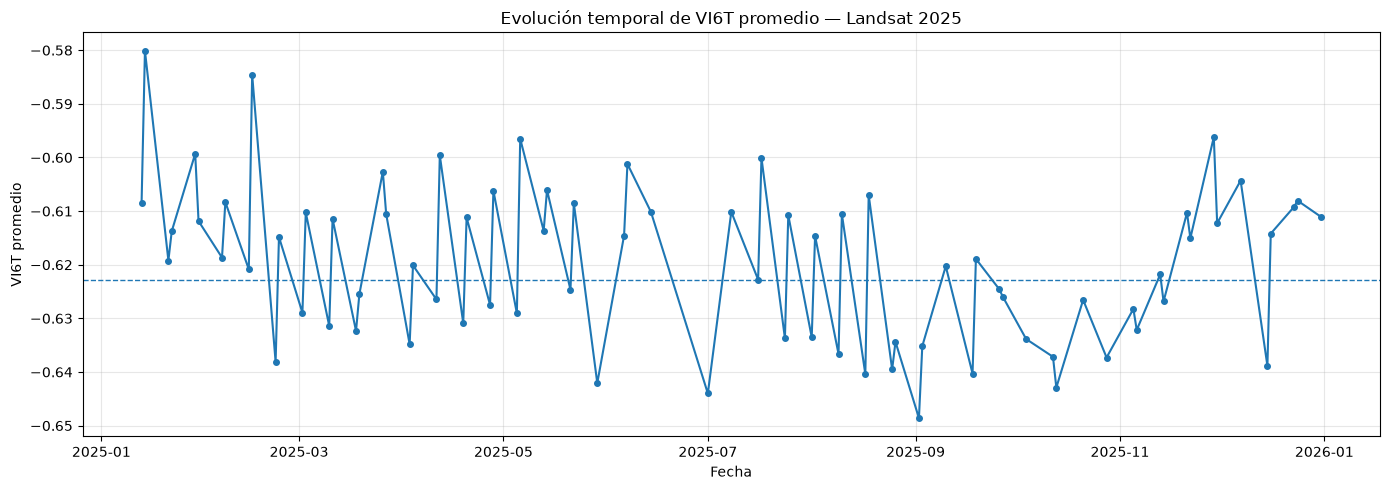

In [116]:
# ============================================================
# EVOLUCIÓN TEMPORAL DEL VI6T PROMEDIO — LANDSAT 2025
# ============================================================

vi6t_grafica = vi6t_por_fecha.dropna(
    subset=["vi6t_promedio"]
).copy()

plt.figure(figsize=(14, 5))

plt.plot(
    vi6t_grafica["fecha_captura"],
    vi6t_grafica["vi6t_promedio"],
    marker="o",
    linewidth=1.5,
    markersize=4
)

plt.axhline(
    vi6t_disponible.mean(),
    linestyle="--",
    linewidth=1
)

plt.title("Evolución temporal de VI6T promedio — Landsat 2025")
plt.xlabel("Fecha")
plt.ylabel("VI6T promedio")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [117]:
# ============================================================
# COBERTURA TEMPORAL DE VI6T POR PARCELA — LANDSAT 2025
# ============================================================

vi6t_por_parcela = (
    landsat_2025
    .groupby("ID_POLIGONO")
    .agg(
        fechas_landsat=("fecha_captura", "nunique"),
        fechas_vi6t=("vi6t_promedio", "count")
    )
    .reset_index()
)

vi6t_por_parcela["porcentaje_vi6t"] = (
    vi6t_por_parcela["fechas_vi6t"]
    / vi6t_por_parcela["fechas_landsat"]
    * 100
)

print("Cobertura temporal de VI6T por parcela — Landsat 2025")
print("-" * 65)

print(
    vi6t_por_parcela[
        ["fechas_landsat", "fechas_vi6t", "porcentaje_vi6t"]
    ].describe()
)

print("\nParcelas con menor disponibilidad de VI6T:")
display(
    vi6t_por_parcela
    .sort_values("porcentaje_vi6t")
    .head(15)
)

print("\nParcelas con mayor disponibilidad de VI6T:")
display(
    vi6t_por_parcela
    .sort_values("porcentaje_vi6t", ascending=False)
    .head(15)
)

Cobertura temporal de VI6T por parcela — Landsat 2025
-----------------------------------------------------------------
       fechas_landsat  fechas_vi6t  porcentaje_vi6t
count      197.000000   197.000000       197.000000
mean        55.512690    37.121827        68.775533
std         16.555907     8.925164        10.784686
min         45.000000    24.000000        32.222222
25%         45.000000    32.000000        66.666667
50%         45.000000    34.000000        71.111111
75%         62.000000    40.000000        75.555556
max         90.000000    65.000000        88.888889

Parcelas con menor disponibilidad de VI6T:


,ID_POLIGONO,fechas_landsat,fechas_vi6t,porcentaje_vi6t
61,AGC_062,90,29,32.222222
138,AGC_139,90,29,32.222222
83,AGC_084,90,32,35.555556
114,AGC_115,90,32,35.555556
72,AGC_073,90,32,35.555556
30,AGC_031,90,33,36.666667
185,AGC_186,90,33,36.666667
7,AGC_008,90,33,36.666667
194,AGC_195,90,33,36.666667
95,AGC_096,90,35,38.888889



Parcelas con mayor disponibilidad de VI6T:


,ID_POLIGONO,fechas_landsat,fechas_vi6t,porcentaje_vi6t
34,AGC_035,45,40,88.888889
183,AGC_184,51,44,86.274510
127,AGC_128,49,42,85.714286
46,AGC_047,45,38,84.444444
19,AGC_020,45,37,82.222222
186,AGC_187,45,37,82.222222
173,AGC_174,45,37,82.222222
145,AGC_146,49,40,81.632653
106,AGC_107,51,41,80.392157
15,AGC_016,51,41,80.392157


In [118]:
# ============================================================
# LANDSAT — VI6T Y NUBOSIDAD — 2025
# ============================================================

landsat_2025["vi6t_disponible_flag"] = (
    landsat_2025["vi6t_promedio"].notna()
)

landsat_2025["grupo_nubosidad"] = pd.cut(
    landsat_2025["porcentaje_nubosidad"],
    bins=[-0.01, 10, 25, 50, 75, 90, 100],
    labels=[
        "0–10%",
        ">10–25%",
        ">25–50%",
        ">50–75%",
        ">75–90%",
        ">90–100%"
    ]
)

tabla_nubosidad_vi6t = (
    landsat_2025
    .groupby("grupo_nubosidad", observed=False)
    .agg(
        observaciones=("vi6t_disponible_flag", "size"),
        vi6t_disponible=("vi6t_disponible_flag", "sum")
    )
    .reset_index()
)

tabla_nubosidad_vi6t["vi6t_faltante"] = (
    tabla_nubosidad_vi6t["observaciones"]
    - tabla_nubosidad_vi6t["vi6t_disponible"]
)

tabla_nubosidad_vi6t["porcentaje_vi6t_disponible"] = (
    tabla_nubosidad_vi6t["vi6t_disponible"]
    / tabla_nubosidad_vi6t["observaciones"]
    * 100
)

display(tabla_nubosidad_vi6t)

,grupo_nubosidad,observaciones,vi6t_disponible,vi6t_faltante,porcentaje_vi6t_disponible
0,0–10%,6480,6480,0,100.000000
1,>10–25%,127,127,0,100.000000
2,>25–50%,201,201,0,100.000000
3,>50–75%,209,209,0,100.000000
4,>75–90%,147,147,0,100.000000
5,>90–100%,3049,149,2900,4.886848


In [119]:
# ============================================================
# LANDSAT — REVISIÓN DETALLADA DE NUBOSIDAD Y VI6T — 2025
# ============================================================

def clasificar_nubosidad(valor):
    if pd.isna(valor):
        return "Nubosidad faltante"
    elif valor == 100:
        return "100%"
    elif valor > 90:
        return ">90–<100%"
    elif valor <= 10:
        return "0–10%"
    elif valor <= 25:
        return ">10–25%"
    elif valor <= 50:
        return ">25–50%"
    elif valor <= 75:
        return ">50–75%"
    elif valor <= 90:
        return ">75–90%"
    else:
        return "Otro"


landsat_2025["grupo_nubosidad_detallado"] = (
    landsat_2025["porcentaje_nubosidad"]
    .apply(clasificar_nubosidad)
)

tabla_detallada = (
    landsat_2025
    .groupby("grupo_nubosidad_detallado", observed=False)
    .agg(
        observaciones=("vi6t_promedio", "size"),
        vi6t_disponible=("vi6t_promedio", "count")
    )
    .reset_index()
)

tabla_detallada["vi6t_faltante"] = (
    tabla_detallada["observaciones"]
    - tabla_detallada["vi6t_disponible"]
)

tabla_detallada["porcentaje_vi6t_disponible"] = (
    tabla_detallada["vi6t_disponible"]
    / tabla_detallada["observaciones"]
    * 100
)

display(tabla_detallada)

,grupo_nubosidad_detallado,observaciones,vi6t_disponible,vi6t_faltante,porcentaje_vi6t_disponible
0,0–10%,6480,6480,0,100.0
1,100%,2900,0,2900,0.0
2,>10–25%,127,127,0,100.0
3,>25–50%,201,201,0,100.0
4,>50–75%,209,209,0,100.0
5,>75–90%,147,147,0,100.0
6,>90–<100%,149,149,0,100.0
7,Nubosidad faltante,723,0,723,0.0


In [120]:
# ============================================================
# LANDSAT — OBSERVACIONES SIN NUBOSIDAD NI VI6T — 2025
# ============================================================

landsat_sin_calidad = landsat_2025[
    landsat_2025["porcentaje_nubosidad"].isna() &
    landsat_2025["vi6t_promedio"].isna()
].copy()

print("Observaciones sin nubosidad ni VI6T")
print("-" * 50)
print(f"Observaciones: {len(landsat_sin_calidad):,}")
print(f"Parcelas: {landsat_sin_calidad['ID_POLIGONO'].nunique():,}")
print(f"Fechas: {landsat_sin_calidad['fecha_captura'].nunique():,}")

print("\nDistribución por mes:")
print("-" * 50)

por_mes = (
    landsat_sin_calidad
    .assign(mes=landsat_sin_calidad["fecha_captura"].dt.month)
    .groupby("mes")
    .size()
    .rename("observaciones")
    .to_frame()
)

display(por_mes)

print("\nFechas con más observaciones sin nubosidad ni VI6T:")
print("-" * 50)

por_fecha = (
    landsat_sin_calidad
    .groupby("fecha_captura")
    .size()
    .sort_values(ascending=False)
    .rename("observaciones")
    .to_frame()
)

display(por_fecha.head(15))

Observaciones sin nubosidad ni VI6T
--------------------------------------------------
Observaciones: 723
Parcelas: 21
Fechas: 45

Distribución por mes:
--------------------------------------------------


,observaciones
mes,
1,65
2,39
3,64
4,57
5,55
6,51
7,72
8,72
9,68



Fechas con más observaciones sin nubosidad ni VI6T:
--------------------------------------------------


,observaciones
fecha_captura,
2025-12-16,19
2025-01-30,18
2025-03-27,18
2025-04-04,18
2025-01-22,18
2025-03-19,18
2025-07-09,18
2025-07-17,18
2025-07-25,18


In [121]:
# ============================================================
# LANDSAT — PATRÓN DE NUBOSIDAD FALTANTE POR PARCELA — 2025
# ============================================================

sin_calidad = landsat_2025[
    landsat_2025["porcentaje_nubosidad"].isna() &
    landsat_2025["vi6t_promedio"].isna()
].copy()

por_parcela_sin_calidad = (
    sin_calidad
    .groupby("ID_POLIGONO")
    .agg(
        observaciones_sin_calidad=("ID_POLIGONO", "size"),
        fechas_distintas=("fecha_captura", "nunique")
    )
    .reset_index()
    .sort_values(
        ["observaciones_sin_calidad", "ID_POLIGONO"],
        ascending=[False, True]
    )
)

print("Observaciones sin nubosidad y sin VI6T — Landsat 2025")
print("-" * 65)

print(f"Total de observaciones: {len(sin_calidad):,}")
print(f"Parcelas afectadas: {sin_calidad['ID_POLIGONO'].nunique():,}")
print(f"Fechas afectadas: {sin_calidad['fecha_captura'].nunique():,}")

print("\nDistribución por parcela:")
display(por_parcela_sin_calidad)

print("\nPrimeras fechas:")
display(
    sin_calidad[
        ["fecha_captura", "ID_POLIGONO"]
    ]
    .sort_values(["fecha_captura", "ID_POLIGONO"])
    .head(30)
)

Observaciones sin nubosidad y sin VI6T — Landsat 2025
-----------------------------------------------------------------
Total de observaciones: 723
Parcelas afectadas: 21
Fechas afectadas: 45

Distribución por parcela:


,ID_POLIGONO,observaciones_sin_calidad,fechas_distintas
0,AGC_008,45,45
2,AGC_031,45,45
3,AGC_062,45,45
5,AGC_073,45,45
7,AGC_084,45,45
9,AGC_096,45,45
10,AGC_115,45,45
13,AGC_139,45,45
18,AGC_186,45,45
20,AGC_195,44,44



Primeras fechas:


,fecha_captura,ID_POLIGONO
71376,2025-01-06,AGC_008
96364,2025-01-06,AGC_031
34991,2025-01-06,AGC_062
42991,2025-01-06,AGC_073
19521,2025-01-06,AGC_082
90711,2025-01-06,AGC_084
60009,2025-01-06,AGC_088
32763,2025-01-06,AGC_096
3526,2025-01-06,AGC_115
55674,2025-01-06,AGC_137


In [122]:
# ============================================================
# LANDSAT — COMPARACIÓN DE LAS 45 FECHAS
# CALENDARIO LANDSAT vs. FECHAS SIN CLOUD + VI6T
# ============================================================

# Calendario de referencia de 45 fechas
calendario_45 = set(calendario_45_referencia)

# Fechas donde existe al menos una observación
# sin nubosidad y sin VI6T
fechas_sin_calidad = set(
    sin_calidad["fecha_captura"].unique()
)

fechas_en_ambos = calendario_45 & fechas_sin_calidad
fechas_solo_calendario = calendario_45 - fechas_sin_calidad
fechas_solo_sin_calidad = fechas_sin_calidad - calendario_45

print("Comparación de calendarios")
print("-" * 60)

print(f"Fechas calendario de 45: {len(calendario_45)}")
print(f"Fechas sin cloud + VI6T: {len(fechas_sin_calidad)}")
print(f"Fechas presentes en ambos: {len(fechas_en_ambos)}")
print(f"Solo en calendario de 45: {len(fechas_solo_calendario)}")
print(f"Solo en fechas sin calidad: {len(fechas_solo_sin_calidad)}")

print("\nFechas que NO coinciden:")
print("-" * 60)

print("Solo calendario 45:")
for fecha in sorted(fechas_solo_calendario):
    print(fecha.date())

print("\nSolo sin calidad:")
for fecha in sorted(fechas_solo_sin_calidad):
    print(fecha.date())

Comparación de calendarios
------------------------------------------------------------
Fechas calendario de 45: 45
Fechas sin cloud + VI6T: 45
Fechas presentes en ambos: 0
Solo en calendario de 45: 45
Solo en fechas sin calidad: 45

Fechas que NO coinciden:
------------------------------------------------------------
Solo calendario 45:
2025-01-05
2025-01-13
2025-01-21
2025-01-29
2025-02-06
2025-02-14
2025-02-22
2025-03-02
2025-03-10
2025-03-18
2025-03-26
2025-04-03
2025-04-11
2025-04-19
2025-04-27
2025-05-05
2025-05-13
2025-05-21
2025-05-29
2025-06-06
2025-06-14
2025-06-22
2025-06-30
2025-07-08
2025-07-16
2025-07-24
2025-08-01
2025-08-09
2025-08-17
2025-08-25
2025-09-02
2025-09-10
2025-09-18
2025-09-26
2025-10-04
2025-10-12
2025-10-28
2025-11-05
2025-11-13
2025-11-21
2025-11-29
2025-12-07
2025-12-15
2025-12-23
2025-12-31

Solo sin calidad:
2025-01-06
2025-01-14
2025-01-22
2025-01-30
2025-02-07
2025-02-15
2025-02-23
2025-03-03
2025-03-11
2025-03-19
2025-03-27
2025-04-04
2025-04-12
202

In [123]:
# ============================================================
# SENTINEL-2 — COBERTURA TEMPORAL 2025
# ============================================================

sentinel_2025 = basico[
    (basico["sensor"] == "Sentinel-2") &
    (basico["fecha_captura"].dt.year == 2025)
].copy()

cobertura_sentinel_fecha = (
    sentinel_2025
    .groupby("fecha_captura")
    .agg(
        parcelas_observadas=("ID_POLIGONO", "nunique")
    )
    .reset_index()
)

cobertura_sentinel_fecha["porcentaje_cobertura"] = (
    cobertura_sentinel_fecha["parcelas_observadas"]
    / 197
    * 100
)

print("Cobertura Sentinel-2 — 2025")
print("-" * 60)

print(f"Observaciones: {len(sentinel_2025):,}")
print(f"Parcelas: {sentinel_2025['ID_POLIGONO'].nunique():,}")
print(f"Fechas: {sentinel_2025['fecha_captura'].nunique():,}")

print("\nCobertura por fecha:")
print(cobertura_sentinel_fecha["porcentaje_cobertura"].describe())

display(cobertura_sentinel_fecha)

Cobertura Sentinel-2 — 2025
------------------------------------------------------------
Observaciones: 16,820
Parcelas: 197
Fechas: 86

Cobertura por fecha:
count     86.000000
mean      99.279896
std        4.694178
min       69.035533
25%      100.000000
50%      100.000000
75%      100.000000
max      100.000000
Name: porcentaje_cobertura, dtype: float64


,fecha_captura,parcelas_observadas,porcentaje_cobertura
0,2025-01-05,197,100.0
1,2025-01-10,197,100.0
2,2025-01-15,197,100.0
3,2025-01-20,197,100.0
4,2025-01-25,197,100.0
...,...,...,...
81,2025-12-13,197,100.0
82,2025-12-16,197,100.0
83,2025-12-21,197,100.0
84,2025-12-26,197,100.0


In [124]:
# ============================================================
# SENTINEL-2 — DISPONIBILIDAD DE NDVI POR FECHA — 2025
# ============================================================

ndvi_por_fecha = (
    sentinel_2025
    .groupby("fecha_captura")
    .agg(
        parcelas_observadas=("ID_POLIGONO", "nunique"),
        ndvi_disponible=("ndvi_promedio", "count"),
        ndvi_promedio=("ndvi_promedio", "mean"),
        ndvi_std=("ndvi_promedio", "std"),
        ndvi_min=("ndvi_promedio", "min"),
        ndvi_max=("ndvi_promedio", "max")
    )
    .reset_index()
)

ndvi_por_fecha["porcentaje_ndvi_disponible"] = (
    ndvi_por_fecha["ndvi_disponible"]
    / ndvi_por_fecha["parcelas_observadas"]
    * 100
)

print("Disponibilidad de NDVI — Sentinel-2 — 2025")
print("-" * 65)

print(
    ndvi_por_fecha["porcentaje_ndvi_disponible"].describe()
)

display(ndvi_por_fecha)

Disponibilidad de NDVI — Sentinel-2 — 2025
-----------------------------------------------------------------
count     86.000000
mean      77.944605
std       32.912974
min        0.000000
25%       71.192893
50%       96.954315
75%      100.000000
max      100.000000
Name: porcentaje_ndvi_disponible, dtype: float64


,fecha_captura,parcelas_observadas,ndvi_disponible,ndvi_promedio,ndvi_std,ndvi_min,ndvi_max,porcentaje_ndvi_disponible
0,2025-01-05,197,0,NaN,NaN,NaN,NaN,0.000000
1,2025-01-10,197,139,0.138576,0.047833,0.013,0.348,70.558376
2,2025-01-15,197,197,0.191736,0.055666,0.114,0.501,100.000000
3,2025-01-20,197,195,0.176031,0.048518,0.112,0.458,98.984772
4,2025-01-25,197,196,0.181046,0.052077,0.107,0.469,99.492386
...,...,...,...,...,...,...,...,...
81,2025-12-13,197,58,0.169155,0.044596,0.030,0.270,29.441624
82,2025-12-16,197,162,0.203475,0.062104,0.053,0.498,82.233503
83,2025-12-21,197,139,0.148424,0.027659,0.088,0.229,70.558376
84,2025-12-26,197,174,0.178247,0.053064,0.011,0.395,88.324873


In [125]:
# ============================================================
# SENTINEL-2 — NDVI Y NUBOSIDAD — 2025
# ============================================================

sentinel_2025["ndvi_disponible_flag"] = (
    sentinel_2025["ndvi_promedio"].notna()
)

sentinel_2025["grupo_nubosidad"] = pd.cut(
    sentinel_2025["porcentaje_nubosidad"],
    bins=[-0.01, 10, 25, 50, 75, 90, 100],
    labels=[
        "0–10%",
        ">10–25%",
        ">25–50%",
        ">50–75%",
        ">75–90%",
        ">90–100%"
    ]
)

tabla_ndvi_nubosidad = (
    sentinel_2025
    .groupby("grupo_nubosidad", observed=False)
    .agg(
        observaciones=("ndvi_disponible_flag", "size"),
        ndvi_disponible=("ndvi_disponible_flag", "sum")
    )
    .reset_index()
)

tabla_ndvi_nubosidad["ndvi_faltante"] = (
    tabla_ndvi_nubosidad["observaciones"]
    - tabla_ndvi_nubosidad["ndvi_disponible"]
)

tabla_ndvi_nubosidad["porcentaje_ndvi_disponible"] = (
    tabla_ndvi_nubosidad["ndvi_disponible"]
    / tabla_ndvi_nubosidad["observaciones"]
    * 100
)

display(tabla_ndvi_nubosidad)

,grupo_nubosidad,observaciones,ndvi_disponible,ndvi_faltante,porcentaje_ndvi_disponible
0,0–10%,11602,11602,0,100.00000
1,>10–25%,344,344,0,100.00000
2,>25–50%,356,356,0,100.00000
3,>50–75%,343,343,0,100.00000
4,>75–90%,257,257,0,100.00000
5,>90–100%,3918,189,3729,4.82389


In [126]:
# ============================================================
# SENTINEL-2 — DISPONIBILIDAD CONJUNTA DE ÍNDICES — 2025
# ============================================================

indices_sentinel = [
    "ndvi_promedio",
    "evi_promedio",
    "lai_promedio",
    "fapar_promedio",
    "ndwi_promedio",
    "msi_promedio"
]

disponibilidad_indices = []

for indice in indices_sentinel:
    disponibilidad_indices.append({
        "indice": indice,
        "disponible": sentinel_2025[indice].notna().sum(),
        "faltante": sentinel_2025[indice].isna().sum(),
        "porcentaje_disponible": (
            sentinel_2025[indice].notna().mean() * 100
        )
    })

tabla_disponibilidad_indices = pd.DataFrame(
    disponibilidad_indices
)

display(tabla_disponibilidad_indices)

,indice,disponible,faltante,porcentaje_disponible
0,ndvi_promedio,13091,3729,77.829964
1,evi_promedio,13091,3729,77.829964
2,lai_promedio,13091,3729,77.829964
3,fapar_promedio,13091,3729,77.829964
4,ndwi_promedio,13091,3729,77.829964
5,msi_promedio,13091,3729,77.829964


In [127]:
# ¿Cuántos índices están disponibles simultáneamente?

sentinel_2025["n_indices_disponibles"] = (
    sentinel_2025[indices_sentinel]
    .notna()
    .sum(axis=1)
)

print("Número de índices disponibles por observación")
print("-" * 60)

display(
    sentinel_2025["n_indices_disponibles"]
    .value_counts()
    .sort_index()
)

print("\nPorcentaje:")
display(
    (
        sentinel_2025["n_indices_disponibles"]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    )
)

Número de índices disponibles por observación
------------------------------------------------------------


n_indices_disponibles
0     3729
6    13091
Name: count, dtype: int64


Porcentaje:


n_indices_disponibles
0    22.170036
6    77.829964
Name: proportion, dtype: float64

In [128]:
# Cobertura temporal Sentinel-2 por parcela en 2025

sentinel_parcela_2025 = (
    sentinel_2025
    .groupby("ID_POLIGONO")
    .agg(
        observaciones=("fecha_captura", "count"),
        indices_disponibles=("n_indices_disponibles", lambda x: (x == 6).sum())
    )
    .reset_index()
)

sentinel_parcela_2025["porcentaje_indices_disponibles"] = (
    sentinel_parcela_2025["indices_disponibles"]
    / sentinel_parcela_2025["observaciones"]
    * 100
)

sentinel_parcela_2025.head(10)

,ID_POLIGONO,observaciones,indices_disponibles,porcentaje_indices_disponibles
0,AGC_001,84,67,79.761905
1,AGC_002,86,65,75.581395
2,AGC_003,86,65,75.581395
3,AGC_004,84,70,83.333333
4,AGC_005,86,65,75.581395
5,AGC_006,86,59,68.604651
6,AGC_007,86,67,77.906977
7,AGC_008,86,68,79.069767
8,AGC_009,86,66,76.744186
9,AGC_010,86,69,80.232558


In [129]:
# Estadísticas de disponibilidad de índices por parcela

sentinel_parcela_2025[
    [
        "observaciones",
        "indices_disponibles",
        "porcentaje_indices_disponibles"
    ]
].describe()

,observaciones,indices_disponibles,porcentaje_indices_disponibles
count,197.000000,197.000000,197.000000
mean,85.380711,66.451777,77.855119
std,0.927050,3.076235,4.027227
min,84.000000,58.000000,67.441860
25%,84.000000,65.000000,75.581395
50%,86.000000,66.000000,77.906977
75%,86.000000,69.000000,80.232558
max,86.000000,72.000000,85.714286


In [130]:
sentinel_parcela_2025.sort_values(
    "porcentaje_indices_disponibles"
).head(10)

,ID_POLIGONO,observaciones,indices_disponibles,porcentaje_indices_disponibles
48,AGC_049,86,58,67.441860
134,AGC_135,86,58,67.441860
126,AGC_127,86,59,68.604651
5,AGC_006,86,59,68.604651
110,AGC_111,86,59,68.604651
107,AGC_108,86,59,68.604651
131,AGC_132,86,59,68.604651
125,AGC_126,86,60,69.767442
12,AGC_013,86,60,69.767442
189,AGC_190,86,61,70.930233


In [131]:
# Planet PRO: auditoría temporal 2025

pro_2025 = pro[
    pro["fecha_captura"].dt.year == 2025
].copy()

pro_2025["indices_disponibles"] = (
    pro_2025[
        [
            "ndvi_promedio",
            "evi_promedio",
            "lai_promedio",
            "msavi_promedio"
        ]
    ]
    .notna()
    .sum(axis=1)
)

print("Observaciones:", len(pro_2025))
print("Parcelas:", pro_2025["ID_POLIGONO"].nunique())
print("Fechas únicas:", pro_2025["fecha_captura"].nunique())
print(
    "Rango:",
    pro_2025["fecha_captura"].min().date(),
    "→",
    pro_2025["fecha_captura"].max().date()
)

Observaciones: 47804
Parcelas: 197
Fechas únicas: 311
Rango: 2025-01-01 → 2025-12-30


In [132]:
# Cobertura temporal de Planet PRO por parcela

pro_parcela_2025 = (
    pro_2025
    .groupby("ID_POLIGONO")
    .agg(
        observaciones=("fecha_captura", "count"),
        indices_disponibles=("indices_disponibles", lambda x: (x == 4).sum())
    )
    .reset_index()
)

pro_parcela_2025["porcentaje_indices_disponibles"] = (
    pro_parcela_2025["indices_disponibles"]
    / pro_parcela_2025["observaciones"]
    * 100
)

pro_parcela_2025.head(10)

,ID_POLIGONO,observaciones,indices_disponibles,porcentaje_indices_disponibles
0,AGC_001,243,182,74.897119
1,AGC_002,246,190,77.235772
2,AGC_003,238,160,67.226891
3,AGC_004,241,189,78.423237
4,AGC_005,245,178,72.653061
5,AGC_006,241,175,72.614108
6,AGC_007,238,155,65.126050
7,AGC_008,246,192,78.048780
8,AGC_009,243,171,70.370370
9,AGC_010,248,187,75.403226


In [133]:
# Estadísticas de disponibilidad de índices Planet PRO por parcela

pro_parcela_2025[
    [
        "observaciones",
        "indices_disponibles",
        "porcentaje_indices_disponibles"
    ]
].describe()

,observaciones,indices_disponibles,porcentaje_indices_disponibles
count,197.000000,197.000000,197.000000
mean,242.659898,181.456853,74.753188
std,4.418314,11.018742,3.927506
min,233.000000,149.000000,63.025210
25%,240.000000,176.000000,72.839506
50%,243.000000,185.000000,75.806452
75%,246.000000,189.000000,77.142857
max,251.000000,202.000000,82.448980


In [134]:
# Disponibilidad de índices Planet según nubosidad

tabla_cloud_pro = (
    pro_2025
    .assign(
        grupo_nubosidad=pd.cut(
            pro_2025["porcentaje_nubosidad"],
            bins=[-np.inf, 10, 25, 50, 75, 90, 100],
            labels=[
                "0-10%",
                ">10-25%",
                ">25-50%",
                ">50-75%",
                ">75-90%",
                ">90-100%"
            ]
        )
    )
    .groupby("grupo_nubosidad", observed=False)
    .agg(
        observaciones=("ID_POLIGONO", "size"),
        indices_disponibles=("indices_disponibles", lambda x: (x == 4).sum())
    )
    .reset_index()
)

tabla_cloud_pro["porcentaje_disponible"] = (
    tabla_cloud_pro["indices_disponibles"]
    / tabla_cloud_pro["observaciones"]
    * 100
)

tabla_cloud_pro

,grupo_nubosidad,observaciones,indices_disponibles,porcentaje_disponible
0,0-10%,31708,31708,100.000000
1,>10-25%,763,763,100.000000
2,>25-50%,967,967,100.000000
3,>50-75%,897,897,100.000000
4,>75-90%,735,735,100.000000
5,>90-100%,12734,677,5.316476


In [135]:
# Separar nubosidad extremadamente alta

def clasificar_nubosidad_pro(x):
    if pd.isna(x):
        return "Nubosidad faltante"
    elif x == 100:
        return "100%"
    elif x > 90:
        return ">90% y <100%"
    else:
        return "<=90%"

pro_2025["grupo_nubosidad_detallado"] = (
    pro_2025["porcentaje_nubosidad"]
    .apply(clasificar_nubosidad_pro)
)

tabla_cloud_pro_detallada = (
    pro_2025
    .groupby("grupo_nubosidad_detallado")
    .agg(
        observaciones=("ID_POLIGONO", "size"),
        indices_disponibles=("indices_disponibles", lambda x: (x == 4).sum())
    )
    .reset_index()
)

tabla_cloud_pro_detallada["porcentaje_disponible"] = (
    tabla_cloud_pro_detallada["indices_disponibles"]
    / tabla_cloud_pro_detallada["observaciones"]
    * 100
)

tabla_cloud_pro_detallada

,grupo_nubosidad_detallado,observaciones,indices_disponibles,porcentaje_disponible
0,100%,12057,0,0.0
1,<=90%,35070,35070,100.0
2,>90% y <100%,677,677,100.0


In [136]:


pro_2025["mes"] = pro_2025["fecha_captura"].dt.month

tabla_mensual_pro = (
    pro_2025
    .groupby("mes")
    .agg(
        observaciones=("ID_POLIGONO", "size"),
        indices_disponibles=("indices_disponibles", lambda x: (x == 4).sum())
    )
    .reset_index()
)

tabla_mensual_pro["porcentaje_disponible"] = (
    tabla_mensual_pro["indices_disponibles"]
    / tabla_mensual_pro["observaciones"]
    * 100
)

tabla_mensual_pro

,mes,observaciones,indices_disponibles,porcentaje_disponible
0,1,4316,3057,70.829472
1,2,4135,3401,82.249093
2,3,5166,4939,95.605885
3,4,4760,4476,94.033613
4,5,4436,3118,70.288548
5,6,2213,1222,55.219160
6,7,2940,1796,61.088435
7,8,4381,3215,73.385072
8,9,3964,2142,54.036327
9,10,3561,2279,63.998877


In [137]:
# Parcelas con al menos una observación Planet útil por mes

parcelas_utiles_mes_pro = (
    pro_2025[pro_2025["indices_disponibles"] == 4]
    .groupby("mes")["ID_POLIGONO"]
    .nunique()
    .reset_index(name="parcelas_con_indices")
)

parcelas_utiles_mes_pro["porcentaje_parcelas"] = (
    parcelas_utiles_mes_pro["parcelas_con_indices"]
    / pro_2025["ID_POLIGONO"].nunique()
    * 100
)

parcelas_utiles_mes_pro

,mes,parcelas_con_indices,porcentaje_parcelas
0,1,197,100.0
1,2,197,100.0
2,3,197,100.0
3,4,197,100.0
4,5,197,100.0
5,6,197,100.0
6,7,197,100.0
7,8,197,100.0
8,9,197,100.0
9,10,197,100.0


In [138]:
# Distribución de observaciones Planet útiles por parcela y mes

pro_util = pro_2025[
    pro_2025["indices_disponibles"] == 4
].copy()

tabla_cobertura_mensual_parcela = (
    pro_util
    .groupby(["mes", "ID_POLIGONO"])
    .size()
    .groupby(level=0)
    .agg(
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max",
        desviacion="std"
    )
    .reset_index()
)

tabla_cobertura_mensual_parcela

,mes,media,mediana,minimo,maximo,desviacion
0,1,15.517766,16.0,12,20,1.683030
1,2,17.263959,18.0,11,21,2.050727
2,3,25.071066,26.0,20,28,2.056603
3,4,22.720812,23.0,17,26,2.318564
4,5,15.827411,16.0,10,20,1.997616
5,6,6.203046,6.0,3,11,1.832081
6,7,9.116751,9.0,4,14,1.919708
7,8,16.319797,16.0,11,20,1.718526
8,9,10.873096,11.0,5,17,2.515085
9,10,11.568528,11.0,7,18,2.792414


In [139]:
# Fechas Planet útiles por mes

fechas_utiles_pro = (
    pro_util
    .groupby("mes")["fecha_captura"]
    .nunique()
    .reset_index(name="fechas_utiles")
)

fechas_utiles_pro

,mes,fechas_utiles
0,1,26
1,2,23
2,3,30
3,4,29
4,5,24
5,6,13
6,7,21
7,8,24
8,9,28
9,10,24


In [140]:
pro_parcela_2025.sort_values(
    "porcentaje_indices_disponibles"
).head(10)

,ID_POLIGONO,observaciones,indices_disponibles,porcentaje_indices_disponibles
66,AGC_067,238,150,63.025210
88,AGC_089,236,149,63.135593
120,AGC_121,234,150,64.102564
77,AGC_078,234,150,64.102564
147,AGC_148,236,153,64.830508
6,AGC_007,238,155,65.126050
139,AGC_140,234,153,65.384615
80,AGC_081,237,157,66.244726
155,AGC_156,237,157,66.244726
33,AGC_034,243,161,66.255144


In [141]:
# Construir fecha mensual a partir de year y month

chirps["fecha"] = pd.to_datetime(
    chirps["year"].astype(str)
    + "-"
    + chirps["month"].astype(str)
    + "-01"
)

print("Filas:", len(chirps))
print("Parcelas:", chirps["ID_POLIGON"].nunique())
print("Fechas únicas:", chirps["fecha"].nunique())
print(
    "Rango:",
    chirps["fecha"].min().date(),
    "→",
    chirps["fecha"].max().date()
)

Filas: 9456
Parcelas: 197
Fechas únicas: 48
Rango: 2022-01-01 → 2025-12-01


In [142]:
chirps = pd.read_csv(CHIRPS_PATH)

print("Columnas:")
print(chirps.columns.tolist())

print("\nPrimeras filas:")
display(chirps.head())

Columnas:
['ID_POLIGON', 'area_weighted_mm', 'n_pixeles', 'suma_pesos', 'area_intersecciones_m2', 'area_parcela_m2', 'year', 'month']

Primeras filas:


,ID_POLIGON,area_weighted_mm,n_pixeles,suma_pesos,area_intersecciones_m2,area_parcela_m2,year,month
0,AGC_001,19.545547,1,1.0,75685.782834,75685.782834,2022,1
1,AGC_001,14.697198,1,1.0,75685.782834,75685.782834,2022,2
2,AGC_001,4.974521,1,1.0,75685.782834,75685.782834,2022,3
3,AGC_001,47.755169,1,1.0,75685.782834,75685.782834,2022,4
4,AGC_001,45.257622,1,1.0,75685.782834,75685.782834,2022,5


In [143]:
# Construir fecha mensual de CHIRPS

chirps["fecha"] = pd.to_datetime(
    chirps["year"].astype(str)
    + "-"
    + chirps["month"].astype(str)
    + "-01"
)

print("Columna fecha creada correctamente.")
print(chirps[["ID_POLIGON", "year", "month", "fecha"]].head())

Columna fecha creada correctamente.
  ID_POLIGON  year  month      fecha
0    AGC_001  2022      1 2022-01-01
1    AGC_001  2022      2 2022-02-01
2    AGC_001  2022      3 2022-03-01
3    AGC_001  2022      4 2022-04-01
4    AGC_001  2022      5 2022-05-01


In [144]:
# Verificar cobertura temporal completa por parcela

cobertura_chirps = (
    chirps
    .groupby("ID_POLIGON")["fecha"]
    .agg(
        meses="nunique",
        fecha_min="min",
        fecha_max="max"
    )
    .reset_index()
)

cobertura_chirps["meses"].describe()

count    197.0
mean      48.0
std        0.0
min       48.0
25%       48.0
50%       48.0
75%       48.0
max       48.0
Name: meses, dtype: float64

In [145]:
# Verificar duplicados parcela-mes en CHIRPS

duplicados_chirps = (
    chirps
    .duplicated(
        subset=["ID_POLIGON", "year", "month"],
        keep=False
    )
)

print("Registros duplicados:", duplicados_chirps.sum())

if duplicados_chirps.sum() > 0:
    display(
        chirps.loc[duplicados_chirps]
        .sort_values(["ID_POLIGON", "year", "month"])
    )

Registros duplicados: 0


In [146]:
# Auditoría de valores de precipitación CHIRPS

print("Valores faltantes:")
print(chirps["area_weighted_mm"].isna().sum())

print("\nValores infinitos:")
print(np.isinf(chirps["area_weighted_mm"]).sum())

print("\nValores negativos:")
print((chirps["area_weighted_mm"] < 0).sum())

print("\nEstadísticas:")
print(chirps["area_weighted_mm"].describe())

Valores faltantes:
0

Valores infinitos:
0

Valores negativos:
0

Estadísticas:
count    9456.000000
mean       69.513798
std        71.652590
min         0.000000
25%        14.562220
50%        38.220311
75%       111.911430
max       392.024017
Name: area_weighted_mm, dtype: float64


In [147]:
# Climatología mensual de precipitación CHIRPS
# Promedio entre parcelas y años para cada mes del calendario

climatologia_chirps = (
    chirps
    .groupby("month")["area_weighted_mm"]
    .agg(
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max"
    )
    .reset_index()
)

climatologia_chirps

,month,media,mediana,minimo,maximo
0,1,12.417198,11.483009,0.000000,32.748020
1,2,15.499972,11.878438,0.000000,61.019646
2,3,13.006343,9.132049,0.000000,54.688824
3,4,23.970043,24.446480,8.309810,48.421150
4,5,75.483473,67.792496,13.668028,232.715652
5,6,129.170396,108.450127,19.379429,366.062653
6,7,155.635743,129.912888,61.024146,382.074951
7,8,140.136608,136.458511,84.784164,243.131470
8,9,129.882506,116.888588,31.889704,392.024017
9,10,88.768367,77.097771,38.594769,167.598251


In [148]:
# Precipitación media mensual específica de 2025

precipitacion_2025 = (
    chirps[chirps["year"] == 2025]
    .groupby("month")["area_weighted_mm"]
    .agg(
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max"
    )
    .reset_index()
)

precipitacion_2025

,month,media,mediana,minimo,maximo
0,1,17.396512,17.910559,11.715059,32.748020
1,2,35.989621,33.402222,21.757489,61.019646
2,3,8.726093,9.088123,4.984048,12.611456
3,4,12.162290,11.679720,8.309810,23.792782
4,5,137.917973,126.606895,91.578702,232.715652
5,6,245.936272,237.676102,195.057495,366.062653
6,7,148.528928,151.622912,101.961647,244.214066
7,8,131.914173,129.185410,94.054337,199.516739
8,9,161.987357,147.459686,110.943595,333.686676
9,10,124.166210,134.713684,70.064331,167.598251


In [149]:
# Precipitación acumulada abril-octubre 2025 por parcela
# Exploración del periodo productivo

precipitacion_ciclo_2025 = (
    chirps[
        (chirps["year"] == 2025)
        & (chirps["month"].between(4, 10))
    ]
    .groupby("ID_POLIGON")["area_weighted_mm"]
    .sum()
    .reset_index(name="precipitacion_abril_octubre_mm")
)

precipitacion_ciclo_2025["precipitacion_abril_octubre_mm"].describe()

count     197.000000
mean      962.613204
std       171.304703
min       702.791300
25%       816.234556
50%       961.350809
75%      1006.236852
max      1459.138424
Name: precipitacion_abril_octubre_mm, dtype: float64

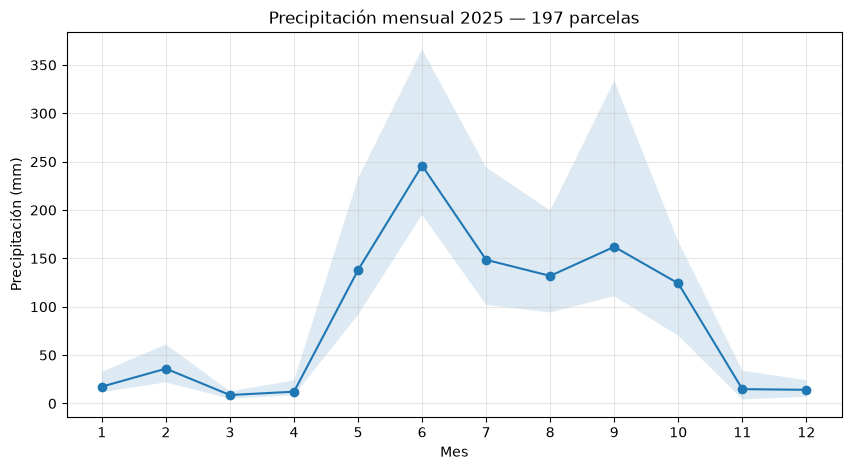

In [150]:
plt.figure(figsize=(10, 5))

plt.plot(
    precipitacion_2025["month"],
    precipitacion_2025["media"],
    marker="o"
)

plt.fill_between(
    precipitacion_2025["month"],
    precipitacion_2025["minimo"],
    precipitacion_2025["maximo"],
    alpha=0.15
)

plt.xticks(range(1, 13))
plt.xlabel("Mes")
plt.ylabel("Precipitación (mm)")
plt.title("Precipitación mensual 2025 — 197 parcelas")
plt.grid(alpha=0.3)

plt.show()

In [151]:
variabilidad_precipitacion_2025 = (
    chirps[chirps["year"] == 2025]
    .groupby("month")["area_weighted_mm"]
    .agg(
        media="mean",
        desviacion_std="std",
        minimo="min",
        maximo="max"
    )
    .reset_index()
)

variabilidad_precipitacion_2025

,month,media,desviacion_std,minimo,maximo
0,1,17.396512,3.672336,11.715059,32.748020
1,2,35.989621,8.363961,21.757489,61.019646
2,3,8.726093,1.565605,4.984048,12.611456
3,4,12.162290,2.781694,8.309810,23.792782
4,5,137.917973,37.233428,91.578702,232.715652
5,6,245.936272,51.414832,195.057495,366.062653
6,7,148.528928,27.286000,101.961647,244.214066
7,8,131.914173,25.736348,94.054337,199.516739
8,9,161.987357,52.516888,110.943595,333.686676
9,10,124.166210,29.947583,70.064331,167.598251


In [152]:
variabilidad_precipitacion_2025["cv"] = (
    variabilidad_precipitacion_2025["desviacion_std"]
    / variabilidad_precipitacion_2025["media"]
)

variabilidad_precipitacion_2025

,month,media,desviacion_std,minimo,maximo,cv
0,1,17.396512,3.672336,11.715059,32.748020,0.211096
1,2,35.989621,8.363961,21.757489,61.019646,0.232399
2,3,8.726093,1.565605,4.984048,12.611456,0.179416
3,4,12.162290,2.781694,8.309810,23.792782,0.228715
4,5,137.917973,37.233428,91.578702,232.715652,0.269968
5,6,245.936272,51.414832,195.057495,366.062653,0.209058
6,7,148.528928,27.286000,101.961647,244.214066,0.183708
7,8,131.914173,25.736348,94.054337,199.516739,0.195099
8,9,161.987357,52.516888,110.943595,333.686676,0.324204
9,10,124.166210,29.947583,70.064331,167.598251,0.241189


In [153]:
TMIN_PATH = (
    DATA_INTERIM
    / "climate"
    / "chirts_era5_tmin_parcel_month_area_weighted.csv"
)

TMAX_PATH = (
    DATA_INTERIM
    / "climate"
    / "chirts_era5_tmax_parcel_month_area_weighted.csv"
)

tmin = pd.read_csv(TMIN_PATH)
tmax = pd.read_csv(TMAX_PATH)

print("TMIN:", tmin.shape)
print("TMAX:", tmax.shape)

print("\nColumnas Tmin:")
print(tmin.columns.tolist())

print("\nColumnas Tmax:")
print(tmax.columns.tolist())

TMIN: (9456, 6)
TMAX: (9456, 6)

Columnas Tmin:
['ID_POLIGON', 'year', 'month', 'TMIN_C', 'n_pixeles', 'suma_pesos']

Columnas Tmax:
['ID_POLIGON', 'year', 'month', 'TMAX_C', 'n_pixeles', 'suma_pesos']


In [154]:
# Auditoría de cobertura y consistencia Tmin/Tmax

keys = ["ID_POLIGON", "year", "month"]

print("TMIN nulls:")
print(tmin[["ID_POLIGON", "year", "month", "TMIN_C"]].isna().sum())

print("\nTMAX nulls:")
print(tmax[["ID_POLIGON", "year", "month", "TMAX_C"]].isna().sum())

print("\nDuplicados Tmin:", tmin.duplicated(keys).sum())
print("Duplicados Tmax:", tmax.duplicated(keys).sum())

print("\nParcelas Tmin:", tmin["ID_POLIGON"].nunique())
print("Parcelas Tmax:", tmax["ID_POLIGON"].nunique())

print("\nPeriodos Tmin:", tmin[["year", "month"]].drop_duplicates().shape[0])
print("Periodos Tmax:", tmax[["year", "month"]].drop_duplicates().shape[0])

# Verificar que ambas fuentes tienen exactamente las mismas claves
keys_tmin = set(map(tuple, tmin[keys].to_numpy()))
keys_tmax = set(map(tuple, tmax[keys].to_numpy()))

print("\nClaves Tmin que no están en Tmax:", len(keys_tmin - keys_tmax))
print("Claves Tmax que no están en Tmin:", len(keys_tmax - keys_tmin))

TMIN nulls:
ID_POLIGON    0
year          0
month         0
TMIN_C        0
dtype: int64

TMAX nulls:
ID_POLIGON    0
year          0
month         0
TMAX_C        0
dtype: int64

Duplicados Tmin: 0
Duplicados Tmax: 0

Parcelas Tmin: 197
Parcelas Tmax: 197

Periodos Tmin: 48
Periodos Tmax: 48

Claves Tmin que no están en Tmax: 0
Claves Tmax que no están en Tmin: 0


In [155]:
print("=== TMIN ===")
print(
    tmin["TMIN_C"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

print("\n=== TMAX ===")
print(
    tmax["TMAX_C"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

# Unir Tmin y Tmax para revisar consistencia
temp_check = tmin[keys + ["TMIN_C"]].merge(
    tmax[keys + ["TMAX_C"]],
    on=keys,
    how="inner",
    validate="one_to_one"
)

temp_check["TMIN_mayor_TMAX"] = temp_check["TMIN_C"] > temp_check["TMAX_C"]

print("\n=== CONSISTENCIA ===")
print("Registros comparados:", len(temp_check))
print("Casos Tmin > Tmax:", temp_check["TMIN_mayor_TMAX"].sum())

print("\nDiferencia Tmin-Tmax:")
print((temp_check["TMAX_C"] - temp_check["TMIN_C"]).describe())

=== TMIN ===
count    9456.000000
mean       11.231370
std         2.540389
min         5.415943
1%          5.954758
5%          7.025712
25%         9.089084
50%        11.551015
75%        13.344477
95%        14.939937
99%        15.867823
max        16.259834
Name: TMIN_C, dtype: float64

=== TMAX ===
count    9456.000000
mean       23.490960
std         2.179852
min        18.760885
1%         19.063272
5%         20.155764
25%        21.980099
50%        23.347312
75%        25.050354
95%        27.145331
99%        29.849874
max        30.158184
Name: TMAX_C, dtype: float64

=== CONSISTENCIA ===
Registros comparados: 9456
Casos Tmin > Tmax: 0

Diferencia Tmin-Tmax:
count    9456.000000
mean       12.259590
std         2.354039
min         7.452831
25%        10.178390
50%        12.421607
75%        14.139731
max        17.810070
dtype: float64


In [156]:
temp_2025 = (
    temp_check
    .query("year == 2025")
    .groupby("month")
    .agg(
        Tmin_media=("TMIN_C", "mean"),
        Tmin_mediana=("TMIN_C", "median"),
        Tmin_min=("TMIN_C", "min"),
        Tmin_max=("TMIN_C", "max"),
        Tmax_media=("TMAX_C", "mean"),
        Tmax_mediana=("TMAX_C", "median"),
        Tmax_min=("TMAX_C", "min"),
        Tmax_max=("TMAX_C", "max"),
    )
    .reset_index()
)

temp_2025

,month,Tmin_media,Tmin_mediana,Tmin_min,Tmin_max,Tmax_media,Tmax_mediana,Tmax_min,Tmax_max
0,1,7.803236,8.277119,6.441164,8.568214,20.934155,20.967552,20.719881,21.140095
1,2,9.541610,10.021509,8.304375,10.434548,22.617038,22.752014,22.228013,22.873215
2,3,10.451386,10.881717,9.285643,11.356604,25.459114,25.589550,25.099869,25.729328
3,4,10.753684,11.312884,9.055782,11.692468,25.918997,25.888519,25.734270,26.225784
4,5,13.782340,14.225541,12.346434,14.473268,26.214156,26.257296,25.471016,26.599937
5,6,14.746647,14.970523,13.426764,15.209744,22.625184,22.686243,22.156263,22.953295
6,7,13.212062,13.493586,11.567570,13.812332,22.933526,23.038158,22.416336,23.353058
7,8,13.352504,13.574040,11.850653,13.901075,23.561403,23.609947,22.799913,23.946495
8,9,13.446730,13.596895,12.201529,13.876060,22.589960,22.675419,22.075449,23.145622
9,10,10.893970,11.192799,9.462555,11.444349,21.870988,21.935844,21.430334,22.338781


In [157]:
temp_climatologia = (
    temp_check
    .groupby("month")
    .agg(
        Tmin_clima_media=("TMIN_C", "mean"),
        Tmin_clima_mediana=("TMIN_C", "median"),
        Tmin_clima_min=("TMIN_C", "min"),
        Tmin_clima_max=("TMIN_C", "max"),
        Tmax_clima_media=("TMAX_C", "mean"),
        Tmax_clima_mediana=("TMAX_C", "median"),
        Tmax_clima_min=("TMAX_C", "min"),
        Tmax_clima_max=("TMAX_C", "max"),
    )
    .reset_index()
)

temp_comparacion = temp_climatologia.merge(
    temp_2025,
    on="month",
    how="inner",
    validate="one_to_one"
)

temp_comparacion

,month,Tmin_clima_media,Tmin_clima_mediana,Tmin_clima_min,Tmin_clima_max,Tmax_clima_media,Tmax_clima_mediana,Tmax_clima_min,Tmax_clima_max,Tmin_media,Tmin_mediana,Tmin_min,Tmin_max,Tmax_media,Tmax_mediana,Tmax_min,Tmax_max
0,1,7.574839,7.511290,5.415943,9.429132,21.271557,21.266044,19.918749,22.411434,7.803236,8.277119,6.441164,8.568214,20.934155,20.967552,20.719881,21.140095
1,2,8.423928,8.334871,6.524603,10.434548,23.128174,23.158468,21.056698,25.047844,9.541610,10.021509,8.304375,10.434548,22.617038,22.752014,22.228013,22.873215
2,3,10.254894,10.259940,8.118088,11.795452,25.613628,25.225458,24.532331,27.294928,10.451386,10.881717,9.285643,11.356604,25.459114,25.589550,25.099869,25.729328
3,4,12.120675,12.344321,9.055782,13.851827,26.114051,25.888519,24.953079,27.612720,10.753684,11.312884,9.055782,11.692468,25.918997,25.888519,25.734270,26.225784
4,5,13.471866,13.012996,10.785013,16.259834,26.726181,26.408041,24.219004,30.158184,13.782340,14.225541,12.346434,14.473268,26.214156,26.257296,25.471016,26.599937
5,6,14.012518,14.207724,11.803316,15.210733,24.663663,24.664122,22.156263,27.400497,14.746647,14.970523,13.426764,15.209744,22.625184,22.686243,22.156263,22.953295
6,7,13.686381,13.589723,11.567570,15.253810,23.532225,23.477032,22.416336,25.001987,13.212062,13.493586,11.567570,13.812332,22.933526,23.038158,22.416336,23.353058
7,8,13.562791,13.574040,11.846639,14.424981,23.632580,23.609947,22.799913,24.366264,13.352504,13.574040,11.850653,13.901075,23.561403,23.609947,22.799913,23.946495
8,9,13.127890,13.089163,10.506974,14.731197,22.671236,22.675419,20.711266,25.267574,13.446730,13.596895,12.201529,13.876060,22.589960,22.675419,22.075449,23.145622
9,10,11.400211,11.385175,9.462555,12.671884,21.896539,21.941648,20.439522,23.689600,10.893970,11.192799,9.462555,11.444349,21.870988,21.935844,21.430334,22.338781


In [158]:
temp_check["DTR_C"] = temp_check["TMAX_C"] - temp_check["TMIN_C"]

dtr_2025 = (
    temp_check[temp_check["year"] == 2025]
    .groupby("month")["DTR_C"]
    .agg(
        media="mean",
        mediana="median",
        minimo="min",
        maximo="max",
        desviacion_std="std"
    )
    .reset_index()
)

dtr_2025

,month,media,mediana,minimo,maximo,desviacion_std
0,1,13.130919,12.704674,12.314199,14.443844,0.720709
1,2,13.075428,12.730505,12.359333,14.073060,0.587179
2,3,15.007727,14.707833,14.355774,15.884783,0.503628
3,4,15.165313,14.575635,14.076524,17.048008,0.988893
4,5,12.431817,12.182500,11.801245,13.325351,0.441748
5,6,7.878537,7.616676,7.452831,8.729499,0.437803
6,7,9.721464,9.378362,9.147369,10.848766,0.590826
7,8,10.208899,9.960724,9.772892,10.949261,0.432615
8,9,9.143230,8.854027,8.678115,9.985208,0.486780
9,10,10.977017,10.599385,10.355981,12.159746,0.649834


In [159]:
variabilidad_temp_2025 = (
    temp_check[temp_check["year"] == 2025]
    .groupby("month")
    .agg(
        Tmin_media=("TMIN_C", "mean"),
        Tmin_std=("TMIN_C", "std"),
        Tmin_min=("TMIN_C", "min"),
        Tmin_max=("TMIN_C", "max"),
        Tmax_media=("TMAX_C", "mean"),
        Tmax_std=("TMAX_C", "std"),
        Tmax_min=("TMAX_C", "min"),
        Tmax_max=("TMAX_C", "max"),
        DTR_media=("DTR_C", "mean"),
        DTR_std=("DTR_C", "std"),
    )
    .reset_index()
)

variabilidad_temp_2025

,month,Tmin_media,Tmin_std,Tmin_min,Tmin_max,Tmax_media,Tmax_std,Tmax_min,Tmax_max,DTR_media,DTR_std
0,1,7.803236,0.699773,6.441164,8.568214,20.934155,0.078535,20.719881,21.140095,13.130919,0.720709
1,2,9.541610,0.761941,8.304375,10.434548,22.617038,0.184054,22.228013,22.873215,13.075428,0.587179
2,3,10.451386,0.709589,9.285643,11.356604,25.459114,0.213804,25.099869,25.729328,15.007727,0.503628
3,4,10.753684,0.865518,9.055782,11.692468,25.918997,0.141241,25.734270,26.225784,15.165313,0.988893
4,5,13.782340,0.645626,12.346434,14.473268,26.214156,0.279833,25.471016,26.599937,12.431817,0.441748
5,6,14.746647,0.445899,13.426764,15.209744,22.625184,0.163992,22.156263,22.953295,7.878537,0.437803
6,7,13.212062,0.577537,11.567570,13.812332,22.933526,0.201618,22.416336,23.353058,9.721464,0.590826
7,8,13.352504,0.522772,11.850653,13.901075,23.561403,0.212045,22.799913,23.946495,10.208899,0.432615
8,9,13.446730,0.422925,12.201529,13.876060,22.589960,0.229047,22.075449,23.145622,9.143230,0.486780
9,10,10.893970,0.546628,9.462555,11.444349,21.870988,0.216293,21.430334,22.338781,10.977017,0.649834


In [160]:
# Temperatura promedio abril-octubre 2025 por parcela

temp_ciclo_2025 = (
    temp_check[
        (temp_check["year"] == 2025)
        & (temp_check["month"].between(4, 10))
    ]
    .groupby("ID_POLIGON")
    .agg(
        Tmin_media_abr_oct=("TMIN_C", "mean"),
        Tmax_media_abr_oct=("TMAX_C", "mean"),
        DTR_media_abr_oct=("DTR_C", "mean"),
    )
    .reset_index()
)

temp_ciclo_2025.describe()

,Tmin_media_abr_oct,Tmax_media_abr_oct,DTR_media_abr_oct
count,197.000000,197.000000,197.000000
mean,12.883991,23.673459,10.789468
std,0.566144,0.155561,0.568475
min,11.415898,23.250251,10.187459
25%,12.280928,23.513994,10.344158
50%,13.248211,23.734426,10.452473
75%,13.328253,23.780726,11.663635
max,13.484572,24.008507,11.834353


In [161]:
# Revisar qué objetos de topografía/elevación existen actualmente
[
    nombre
    for nombre in globals()
    if any(
        palabra in nombre.lower()
        for palabra in ["elev", "topo", "slope", "pendiente"]
    )
]

['TOPO_PATH', 'topografia', 'temp_topografia', 'correlacion_elevacion']

In [162]:
from pathlib import Path

print("Directorio actual:")
print(Path.cwd())

print("\nContenido del directorio actual:")
for item in Path.cwd().iterdir():
    print(" -", item.name)

Directorio actual:
c:\Users\nonoe\OneDrive\Escritorio\Proyectos\AgroCebada-FIRA-2026\notebooks

Contenido del directorio actual:
 - 01_auditoria_geoespacial.ipynb
 - 02_auditoria_precipitacion.ipynb
 - 03_auditoria_temperatura.ipynb
 - 04_auditoria_topografia.ipynb
 - 05_auditoria_fuentes_satelitales.ipynb
 - 06_auditoria_temporal.ipynb


In [163]:
# ============================================================
# CARGA DE TOPOGRAFÍA YA AUDITADA
# ============================================================

topografia = pd.read_csv(TOPO_PATH)

print("Shape:", topografia.shape)

print("\nColumnas:")
print(topografia.columns.tolist())

print("\nDuplicados ID:")
print(topografia["ID_POLIGON"].duplicated().sum())

print("\nIDs únicos:")
print(topografia["ID_POLIGON"].nunique())

print("\nValores nulos:")
print(topografia.isna().sum())

Shape: (197, 5)

Columnas:
['ID_POLIGON', 'slope_deg', 'slope_coverage', 'elevation_m', 'elevation_coverage']

Duplicados ID:
0

IDs únicos:
197

Valores nulos:
ID_POLIGON            0
slope_deg             0
slope_coverage        0
elevation_m           0
elevation_coverage    0
dtype: int64


In [164]:
# ============================================================
# UNIÓN Y VALIDACIÓN DE TEMPERATURA
# Tmin + Tmax
# ============================================================

keys = ["ID_POLIGON", "year", "month"]

temp_check = tmin[keys + ["TMIN_C"]].merge(
    tmax[keys + ["TMAX_C"]],
    on=keys,
    how="inner",
    validate="one_to_one"
)

# Diferencia térmica diaria/media mensual:
# DTR = Tmax - Tmin
temp_check["DTR_C"] = (
    temp_check["TMAX_C"] - temp_check["TMIN_C"]
)

print("Shape:", temp_check.shape)

print("\nColumnas:")
print(temp_check.columns.tolist())

print("\nDuplicados por parcela-periodo:")
print(
    temp_check.duplicated(
        subset=["ID_POLIGON", "year", "month"]
    ).sum()
)

print("\nValores nulos:")
print(
    temp_check[
        ["TMIN_C", "TMAX_C", "DTR_C"]
    ].isna().sum()
)

print("\nCasos Tmin > Tmax:")
print(
    (temp_check["TMIN_C"] > temp_check["TMAX_C"]).sum()
)

Shape: (9456, 6)

Columnas:
['ID_POLIGON', 'year', 'month', 'TMIN_C', 'TMAX_C', 'DTR_C']

Duplicados por parcela-periodo:
0

Valores nulos:
TMIN_C    0
TMAX_C    0
DTR_C     0
dtype: int64

Casos Tmin > Tmax:
0


In [165]:
# ============================================================
# TEMPERATURA DEL CICLO 2025 + TOPOGRAFÍA
# Abril–Octubre
# ============================================================

temp_ciclo_2025 = (
    temp_check[
        (temp_check["year"] == 2025)
        & (temp_check["month"].between(4, 10))
    ]
    .groupby("ID_POLIGON")
    .agg(
        Tmin_media_abr_oct=("TMIN_C", "mean"),
        Tmax_media_abr_oct=("TMAX_C", "mean"),
        DTR_media_abr_oct=("DTR_C", "mean"),
    )
    .reset_index()
)

temp_topografia = temp_ciclo_2025.merge(
    topografia[
        [
            "ID_POLIGON",
            "elevation_m",
            "slope_deg",
            "elevation_coverage",
            "slope_coverage",
        ]
    ],
    on="ID_POLIGON",
    how="inner",
    validate="one_to_one",
)

print("Shape:", temp_topografia.shape)

print("\nDuplicados ID:")
print(temp_topografia["ID_POLIGON"].duplicated().sum())

print("\nValores nulos:")
print(temp_topografia.isna().sum())

Shape: (197, 8)

Duplicados ID:
0

Valores nulos:
ID_POLIGON            0
Tmin_media_abr_oct    0
Tmax_media_abr_oct    0
DTR_media_abr_oct     0
elevation_m           0
slope_deg             0
elevation_coverage    0
slope_coverage        0
dtype: int64


In [166]:
# ============================================================
# RELACIÓN ENTRE TEMPERATURA DEL CICLO Y ELEVACIÓN
# ============================================================

variables_clima = [
    "Tmin_media_abr_oct",
    "Tmax_media_abr_oct",
    "DTR_media_abr_oct",
]

correlacion_elevacion = temp_topografia[
    variables_clima + ["elevation_m"]
].corr(method="pearson")["elevation_m"].drop("elevation_m")

print("Correlación de Pearson con elevación:")
print(correlacion_elevacion)

Correlación de Pearson con elevación:
Tmin_media_abr_oct    0.209521
Tmax_media_abr_oct   -0.672532
DTR_media_abr_oct    -0.392699
Name: elevation_m, dtype: float64


In [167]:
# ============================================================
# PEARSON vs SPEARMAN
# ============================================================

correlaciones = temp_topografia[
    [
        "Tmin_media_abr_oct",
        "Tmax_media_abr_oct",
        "DTR_media_abr_oct",
        "elevation_m",
    ]
].corr(method="spearman")["elevation_m"].drop("elevation_m")

print("Correlación de Spearman con elevación:")
print(correlaciones)

Correlación de Spearman con elevación:
Tmin_media_abr_oct    0.021552
Tmax_media_abr_oct   -0.680199
DTR_media_abr_oct    -0.359134
Name: elevation_m, dtype: float64


In [168]:
# ============================================================
# CONTROL DE CALIDAD DE COBERTURA TOPOGRÁFICA
# ============================================================

temp_topografia[
    [
        "elevation_coverage",
        "slope_coverage"
    ]
].describe()

,elevation_coverage,slope_coverage
count,197.000000,197.000000
mean,0.998210,0.987273
std,0.017765,0.094683
min,0.759380,0.020969
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,1.000000,1.000000
